# Step 8 – Comparison and Evaluation
**Project:** Paper Leak Sentiment Analysis Using Federated Learning – **Objective 3**

> *Compare the federated model with centralized and locally trained models using accuracy, precision, recall and F1-score.*

| # | Question | Experiment |
|---|---|---|
| 1 | How close does federated learning get to centralized training? | Centralized vs FedAvg vs Local-only (3 random seeds) |
| 2 | Why should platforms collaborate at all? | Each local model tested on every other platform |
| 3 | Who benefits most from collaboration? | Accuracy by language |
| 4 | Does uneven (non-IID) data hurt FedAvg? Does FedProx help? | Non-IID vs IID clients, FedProx |
| 5 | How much accuracy does extra privacy protection cost? | Gaussian noise on client updates |

All models use the **same softmax model, the same hashing features and the same 10,000-comment test set**, so the comparison is fair.
The experiments are run by `src/evaluate.py` (about 15 minutes). This notebook loads their saved results; set `RUN_EXPERIMENTS = True` to run them again.

In [1]:
RUN_EXPERIMENTS = False

import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
if RUN_EXPERIMENTS:
    import evaluate; evaluate.main()

from matplotlib import font_manager
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
PLATFORMS = ["YouTube", "X", "Instagram", "Reddit", "NewsPortal"]
plt.rcParams.update({"font.family": FONT, "font.size": 10, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
def title(ax, main, sub=None):
    ax.set_title(main, loc="left", fontsize=13, fontweight="bold", color=INK, pad=24 if sub else 10)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")
main   = pd.read_csv(TAB / "comparison_main.csv")
cross  = pd.read_csv(TAB / "cross_platform_accuracy.csv", index_col=0)
lang   = pd.read_csv(TAB / "accuracy_by_language.csv")
prox   = pd.read_csv(TAB / "fedprox_results.csv")
curves = pd.read_csv(TAB / "convergence_curves.csv")
noise  = pd.read_csv(TAB / "privacy_noise_tradeoff.csv")
svm    = pd.read_csv(TAB / "centralized_results.csv").iloc[0]

## 1. Main result: centralized vs federated vs local-only

In [2]:
t = main.copy()
t["Privacy"] = np.where(t.method.str.startswith("Centralized"), "❌ data pooled", "✅ no data shared")
t["Accuracy (mean ± std)"] = [f"{m:.2%} ± {s:.2%}" for m, s in zip(t.accuracy_mean, t.accuracy_std)]
t = t[["method", "Privacy", "Accuracy (mean ± std)", "precision", "recall", "macro_f1_mean"]]
t.columns = ["Method", "Privacy", "Accuracy (mean ± std)", "Precision", "Recall", "Macro-F1"]
t.style.format({c: "{:.2%}" for c in ["Precision", "Recall", "Macro-F1"]}).hide(axis="index")

Method,Privacy,Accuracy (mean ± std),Precision,Recall,Macro-F1
Centralized (pooled data),❌ data pooled,92.25% ± 0.02%,92.35%,92.25%,92.22%
FedAvg – platform clients (non-IID),✅ no data shared,91.94% ± 0.03%,92.03%,91.94%,91.91%
FedAvg – random clients (IID),✅ no data shared,92.00% ± 0.01%,92.09%,92.00%,91.97%
Local only – YouTube,✅ no data shared,91.12% ± 0.03%,91.30%,91.12%,91.08%
Local only – X,✅ no data shared,91.46% ± 0.04%,91.55%,91.46%,91.43%
Local only – Instagram,✅ no data shared,90.79% ± 0.02%,90.99%,90.79%,90.74%
Local only – Reddit,✅ no data shared,90.42% ± 0.05%,90.44%,90.42%,90.40%
Local only – NewsPortal,✅ no data shared,88.70% ± 0.44%,88.70%,88.70%,88.69%
Local only – average of 5 platforms,✅ no data shared,90.50% ± 0.09%,90.60%,90.50%,90.47%


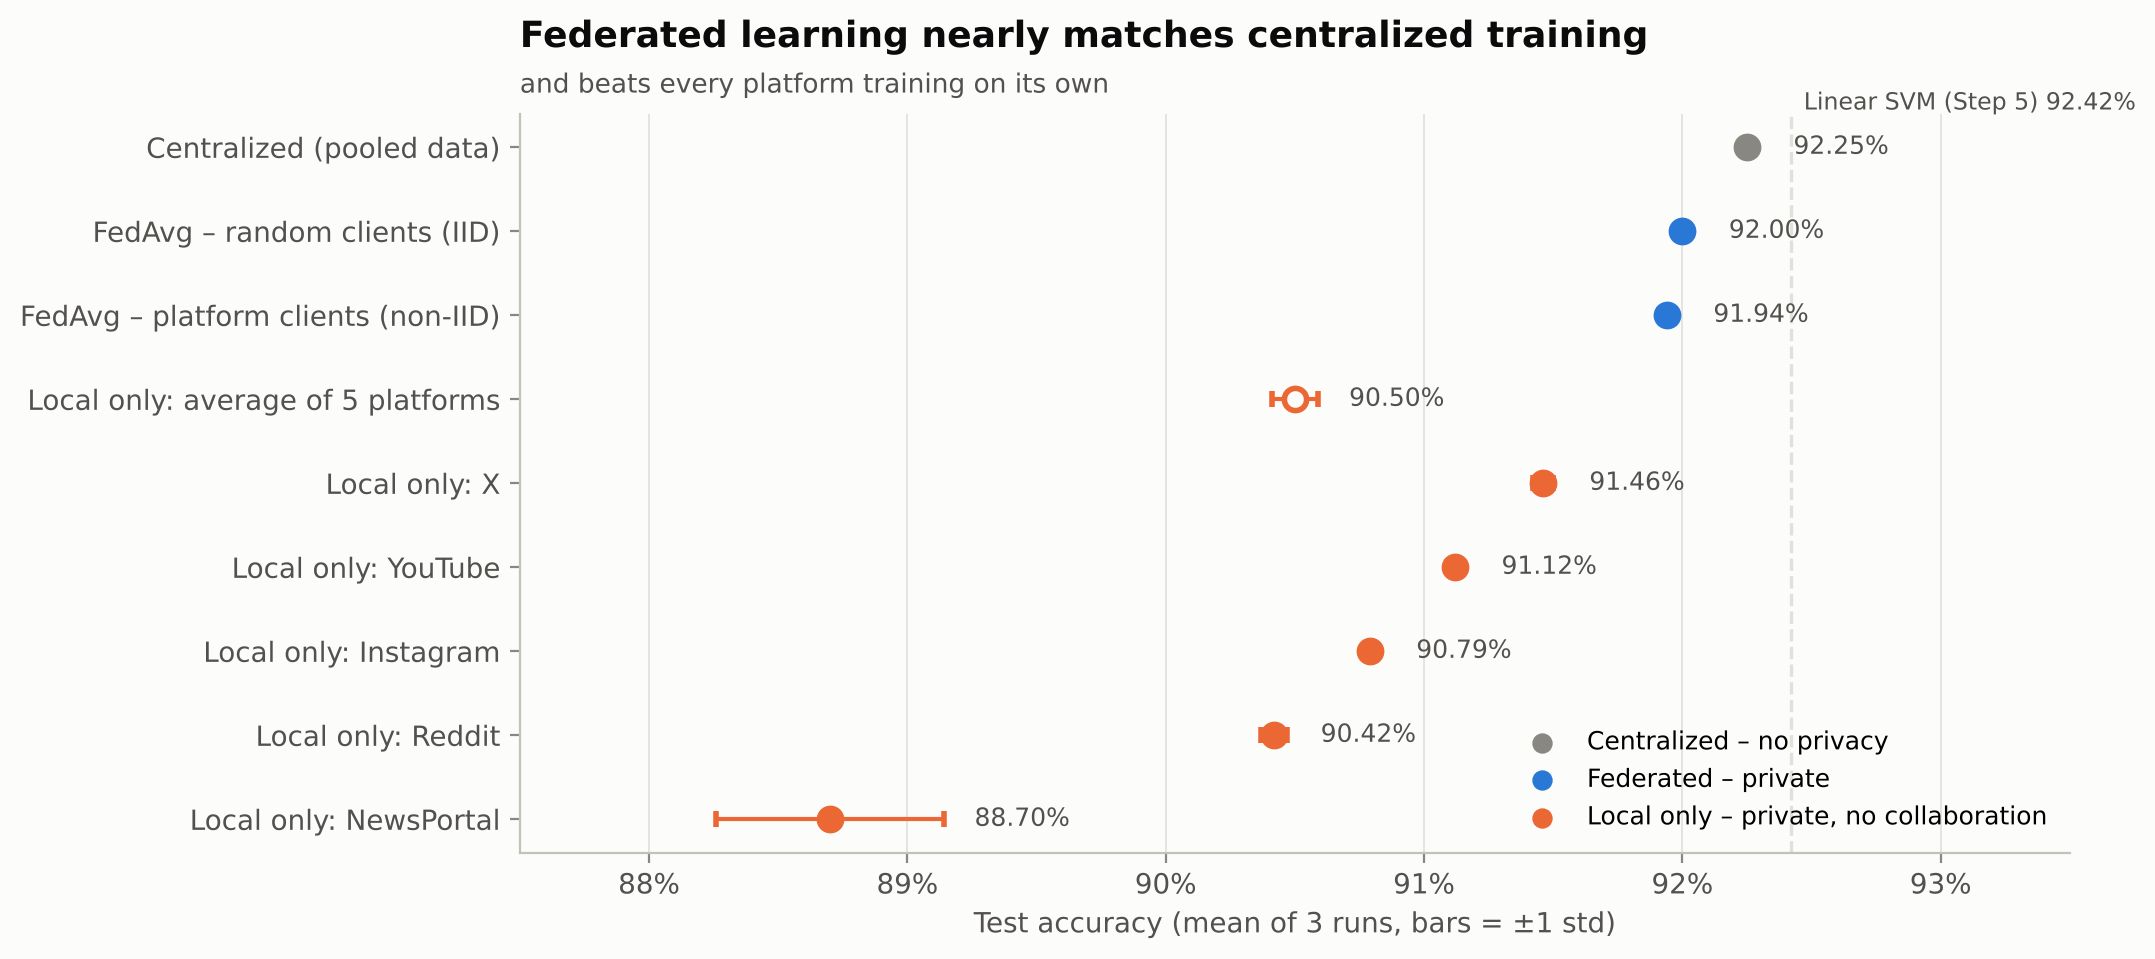

In [3]:
order = ["Centralized (pooled data)", "FedAvg – random clients (IID)", "FedAvg – platform clients (non-IID)",
         "Local only – average of 5 platforms", "Local only – X", "Local only – YouTube", "Local only – Instagram",
         "Local only – Reddit", "Local only – NewsPortal"]
m = main.set_index("method").loc[order].iloc[::-1]
col = lambda n: MUTED if n.startswith("Centralized") else (BLUE if n.startswith("FedAvg") else ORANGE)
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, (name, r) in enumerate(m.iterrows()):
    ax.errorbar(r.accuracy_mean, i, xerr=r.accuracy_std, fmt="o", ms=8, color=col(name), ecolor=col(name), capsize=3,
                mfc=col(name) if "average" not in name else SURFACE, mew=2)
    ax.text(r.accuracy_mean + max(r.accuracy_std, 0.0006) + 0.0012, i, f"{r.accuracy_mean:.2%}", va="center", fontsize=9, color=INK2)
ax.axvline(svm.accuracy, color=GRID, lw=1.2, ls="--")
ax.text(svm.accuracy + 0.0005, 8.45, f"Linear SVM (Step 5) {svm.accuracy:.2%}", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(m)), [n.replace("Local only – ", "Local only: ") for n in m.index]); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_xlim(0.875, 0.935); ax.set_xlabel("Test accuracy (mean of 3 runs, bars = ±1 std)")
for lbl, c in [("Centralized – no privacy", MUTED), ("Federated – private", BLUE), ("Local only – private, no collaboration", ORANGE)]:
    ax.scatter([], [], color=c, s=40, label=lbl)
ax.legend(loc="lower right", fontsize=9)
title(ax, "Federated learning nearly matches centralized training", "and beats every platform training on its own")
fig.savefig(FIG / "G1_main_comparison.png"); plt.show()

In [4]:
c, f, l = (main.set_index("method").loc[k, "accuracy_mean"] for k in
           ["Centralized (pooled data)", "FedAvg – platform clients (non-IID)", "Local only – average of 5 platforms"])
print(f"Cost of privacy   (centralized - FedAvg)      : {(c - f) * 100:.2f} percentage points")
print(f"Gain from sharing (FedAvg - average local-only): {(f - l) * 100:.2f} percentage points")
print(f"FedAvg recovers {(f - l) / (c - l):.0%} of the gap between training alone and pooling all data")

Cost of privacy   (centralized - FedAvg)      : 0.31 percentage points
Gain from sharing (FedAvg - average local-only): 1.44 percentage points
FedAvg recovers 82% of the gap between training alone and pooling all data


- **FedAvg reaches 91.94%**, only about **0.3 points** below centralized training (92.25%), without any platform sharing its comments.
- Every platform does better through FedAvg than by **training alone**. The average local model reaches 90.5%, and NewsPortal alone only 88.7%.
- The small standard deviations (≤0.05 points for most methods; 0.44 for local NewsPortal) show the results are **stable**, not luck from one run.

## 2. Why collaborate? A model trained on one platform struggles on others

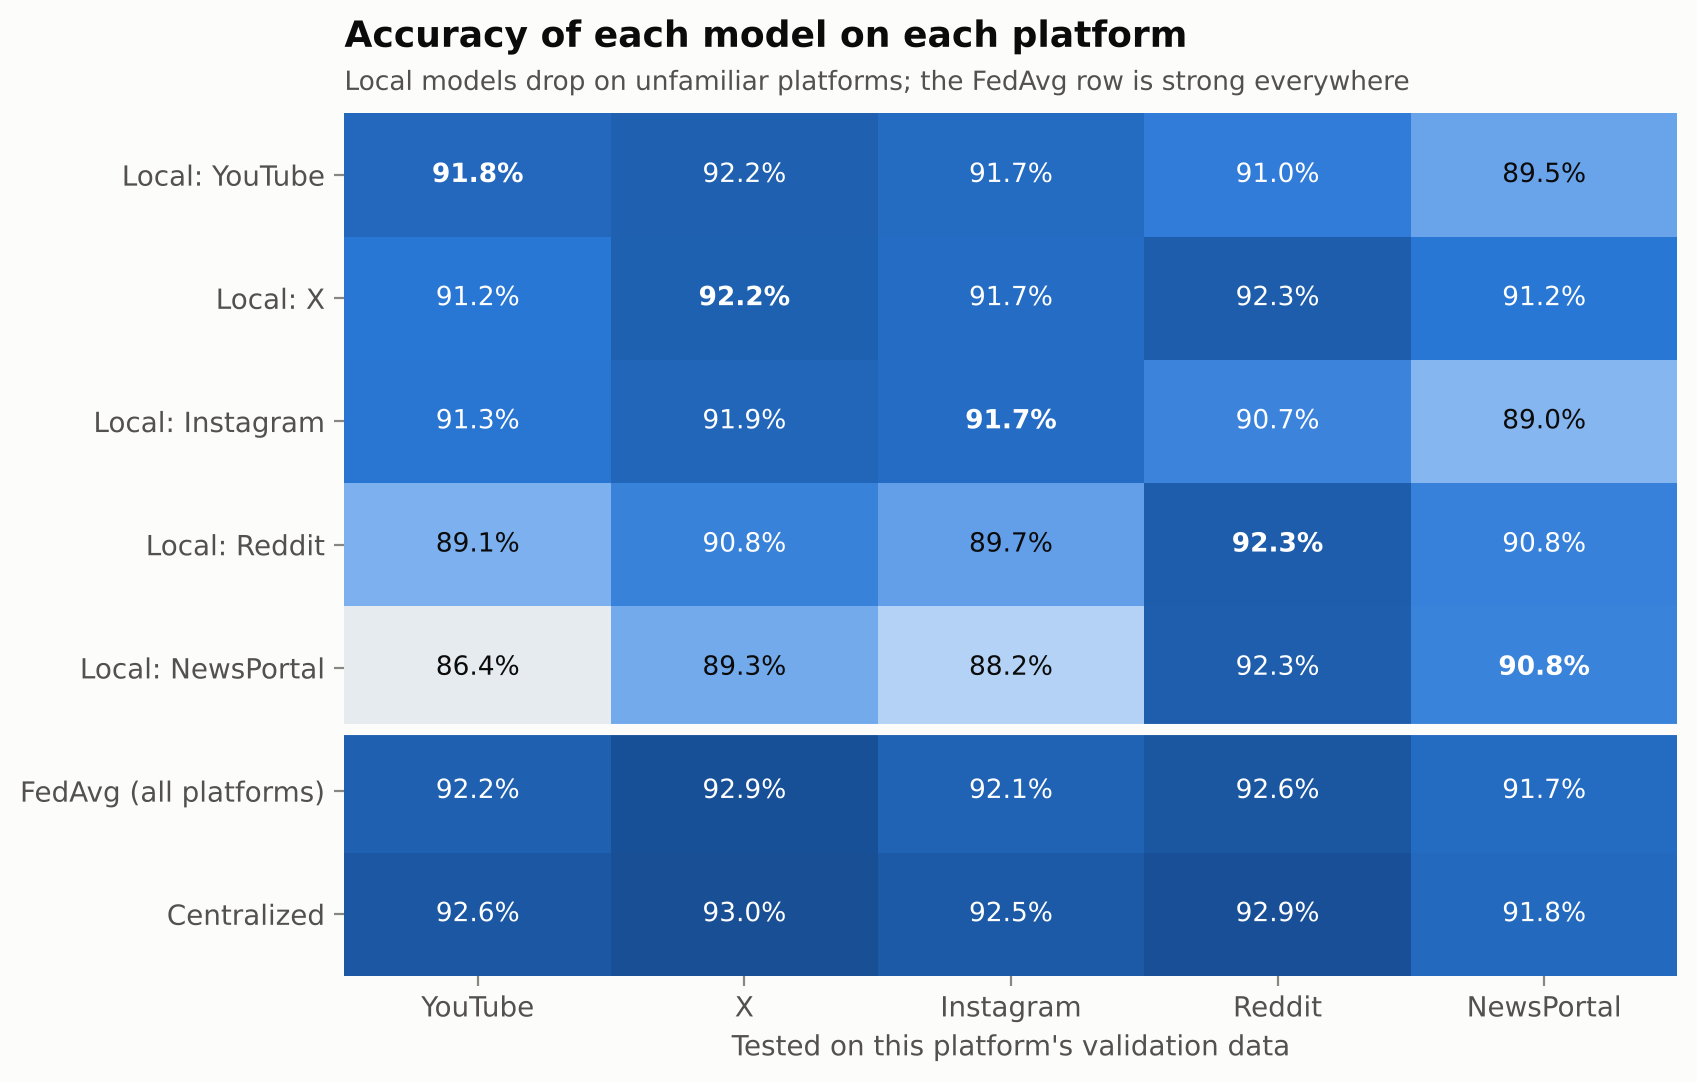

In [5]:
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("b", ["#f0efec", "#cde2fb", "#6da7ec", "#2a78d6", "#184f95"])
C = cross.loc[PLATFORMS + ["FedAvg (all platforms)", "Centralized"], PLATFORMS]
vmin, vmax = C.values.min() - 0.005, C.values.max()
fig, ax = plt.subplots(figsize=(8.6, 5.6))
ax.imshow(C.values, cmap=blues, vmin=vmin, vmax=vmax, aspect="auto")
for i in range(C.shape[0]):
    for j in range(C.shape[1]):
        v = C.values[i, j]
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=9.5,
                color="#ffffff" if (v - vmin) / (vmax - vmin) > 0.6 else INK, fontweight="bold" if i < 5 and i == j else None)
ax.axhline(4.5, color=SURFACE, lw=4)
ax.set_xticks(range(5), PLATFORMS); ax.set_yticks(range(C.shape[0]), [f"Local: {p}" for p in PLATFORMS] + ["FedAvg (all platforms)", "Centralized"])
ax.set_xlabel("Tested on this platform's validation data"); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
title(ax, "Accuracy of each model on each platform", "Local models drop on unfamiliar platforms; the FedAvg row is strong everywhere")
fig.savefig(FIG / "G2_cross_platform.png"); plt.show()

- The **NewsPortal-only model scores 86.4% on YouTube**, because it has barely seen Hinglish. The FedAvg model scores **92.2%** there.
- Each local model is good on its own platform but weaker elsewhere. The **FedAvg row is high on every platform**, almost the same as the centralized row.

## 3. Who benefits most? Accuracy by language

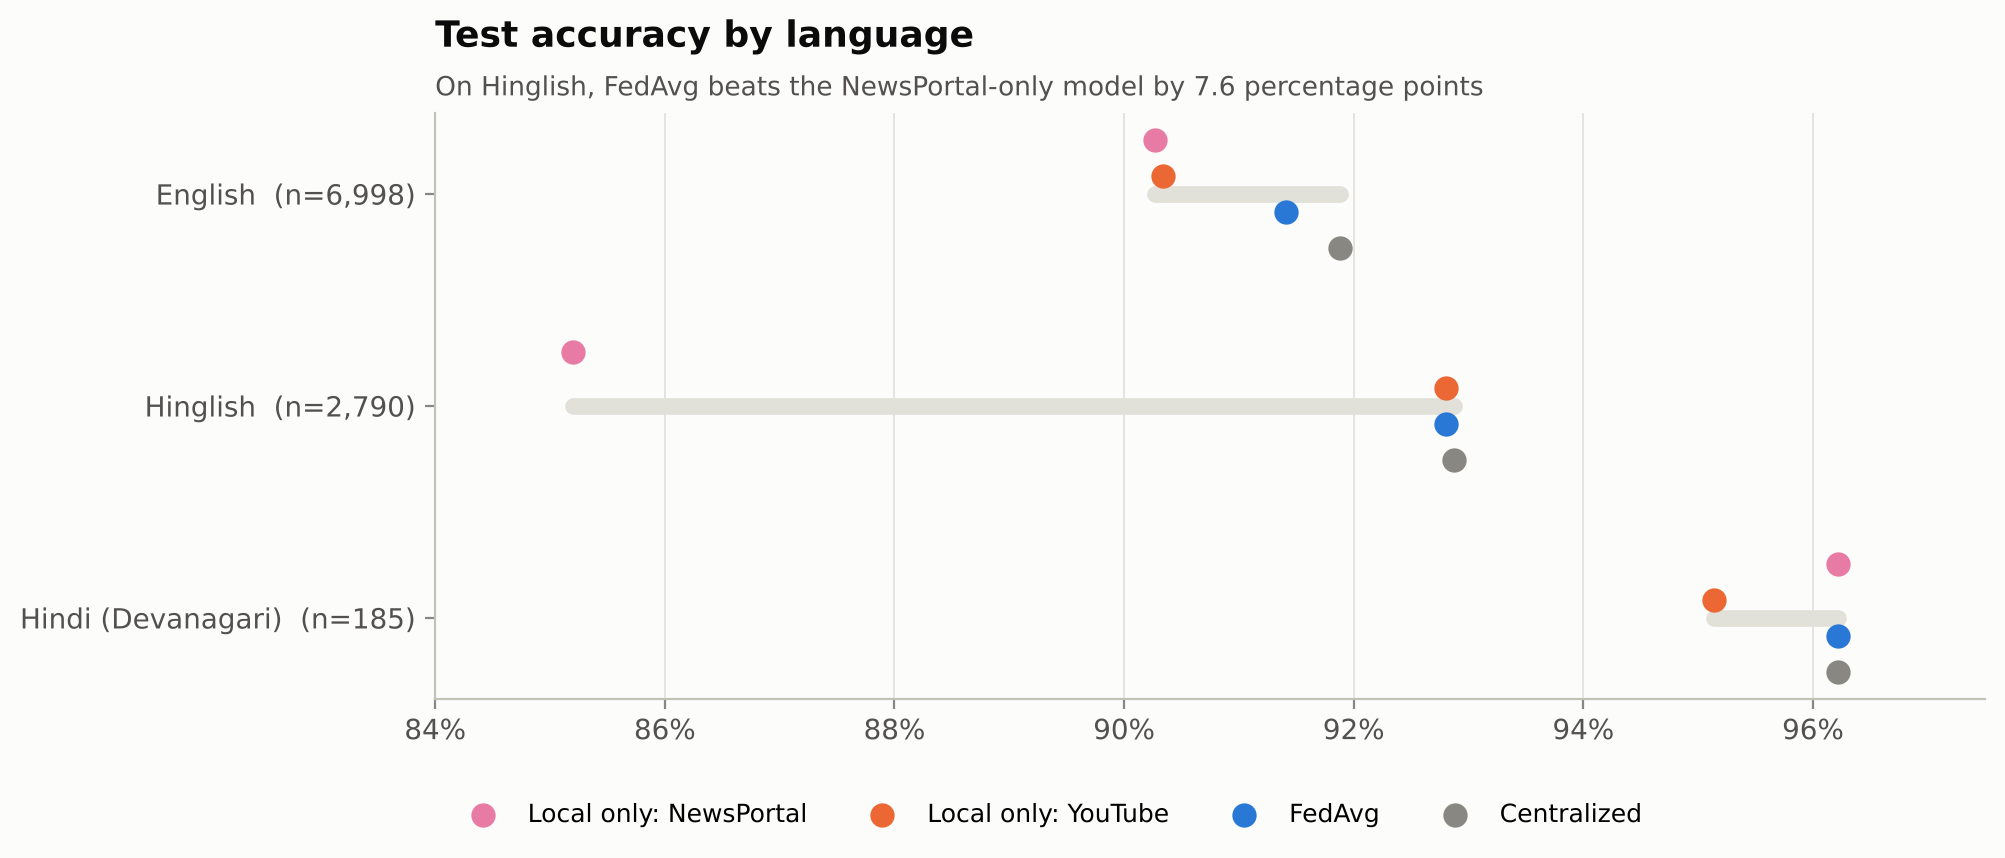

In [6]:
names = {"en": "English", "hinglish": "Hinglish", "hi": "Hindi (Devanagari)"}
models = ["Local only – NewsPortal", "Local only – YouTube", "FedAvg", "Centralized"]
mcol = {"Local only – NewsPortal": "#e87ba4", "Local only – YouTube": ORANGE, "FedAvg": BLUE, "Centralized": MUTED}
L = lang[lang.language.isin(names)].pivot(index="language", columns="model", values="accuracy").loc[list(names)]
n = lang.drop_duplicates("language").set_index("language").comments
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, mname in enumerate(models):
    y = np.arange(3) + (k - 1.5) * 0.17
    ax.scatter(L[mname], y, s=60, color=mcol[mname], label=mname.replace("Local only – ", "Local only: "), zorder=3)
for i, lg in enumerate(names):
    ax.plot([L.loc[lg].min(), L.loc[lg].max()], [i, i], color=GRID, lw=6, zorder=1, solid_capstyle="round")
ax.set_yticks(range(3), [f"{names[l]}  (n={n[l]:,})" for l in names]); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_xlim(0.84, 0.975); ax.invert_yaxis()
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.14), fontsize=9)
gap = L.loc["hinglish", "FedAvg"] - L.loc["hinglish", "Local only – NewsPortal"]
title(ax, "Test accuracy by language", f"On Hinglish, FedAvg beats the NewsPortal-only model by {gap * 100:.1f} percentage points")
fig.savefig(FIG / "G3_accuracy_by_language.png"); plt.show()

The English-only NewsPortal client gains the most from federated learning. On **Hinglish** comments its own model reaches only **85.2%**, while the shared FedAvg model reaches **92.8%**. NewsPortal never had to see a single YouTube comment to get that improvement.

## 4. Non-IID vs IID clients, and FedProx

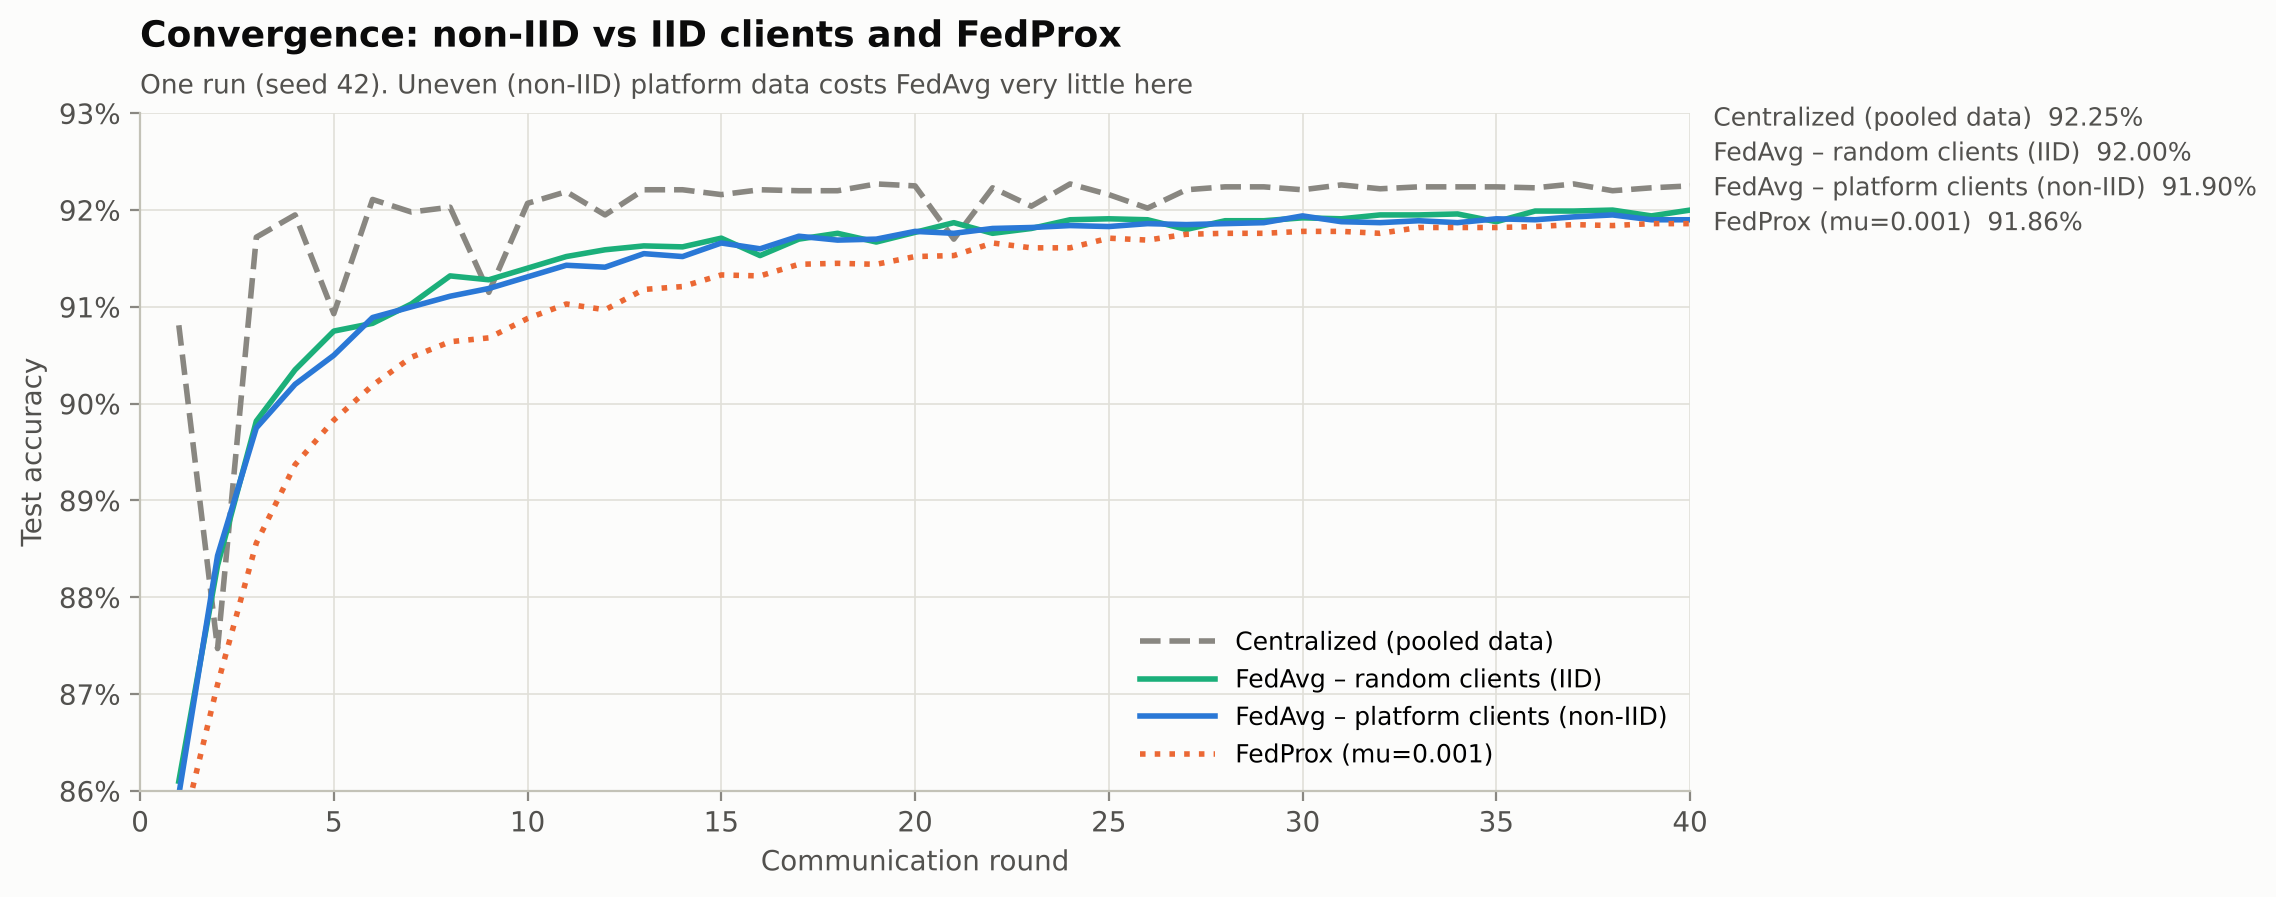

mu,accuracy,precision,recall,macro_f1
0 (plain FedAvg),91.90%,91.99%,91.90%,91.87%
0.0003,91.87%,91.96%,91.87%,91.84%
0.001,91.86%,91.95%,91.86%,91.83%
0.003,91.54%,91.62%,91.54%,91.51%


In [7]:
show = {"Centralized (pooled data)": (MUTED, "--"), "FedAvg – random clients (IID)": (GREEN, "-"),
        "FedAvg – platform clients (non-IID)": (BLUE, "-"), "FedProx (mu=0.001)": (ORANGE, ":")}
fig, ax = plt.subplots(figsize=(10, 4.4))
ends = []
for name, (c, ls) in show.items():
    g = curves[curves.method == name]
    ax.plot(g["round"], g.test_accuracy, color=c, lw=2, ls=ls, label=name)
    ends.append((g.test_accuracy.iloc[-1], name, c))
ends.sort(); ypos = []
for v, name, c in ends:
    y = v if not ypos else max(v, ypos[-1] + 0.0036); ypos.append(y)
    ax.text(40.6, y, f"{name}  {v:.2%}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 40); ax.set_ylim(0.86, 0.93); ax.set_xlabel("Communication round")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylabel("Test accuracy")
ax.legend(loc="lower right", fontsize=9, handlelength=3)
title(ax, "Convergence: non-IID vs IID clients and FedProx", "One run (seed 42). Uneven (non-IID) platform data costs FedAvg very little here")
fig.savefig(FIG / "G4_convergence_iid_fedprox.png"); plt.show()
prox.assign(mu=prox.mu.map(lambda x: "0 (plain FedAvg)" if x == 0 else str(x))) \
    .style.format({c: "{:.2%}" for c in ["accuracy", "precision", "recall", "macro_f1"]}).hide(axis="index")

- **IID vs non-IID:** with random, identical-looking clients, FedAvg reaches 92.00%; with the realistic platform clients, 91.94%. The non-IID penalty is only about **0.06 points**, because our platforms differ moderately and the model is a simple convex (linear) one.
- **FedProx did not help** (91.86% at μ=0.001, 91.54% at μ=0.003). FedProx is designed for strongly non-IID data and deep models. With this level of heterogeneity, plain FedAvg is enough. This is an honest negative result, and it is worth reporting.

## 5. Extra privacy: adding noise to the updates

Model weights can still leak some information about training data. A standard defence (as in **differential privacy**) is to **clip** each client's update and add **Gaussian noise** on the server before averaging. More noise means more protection and less accuracy.

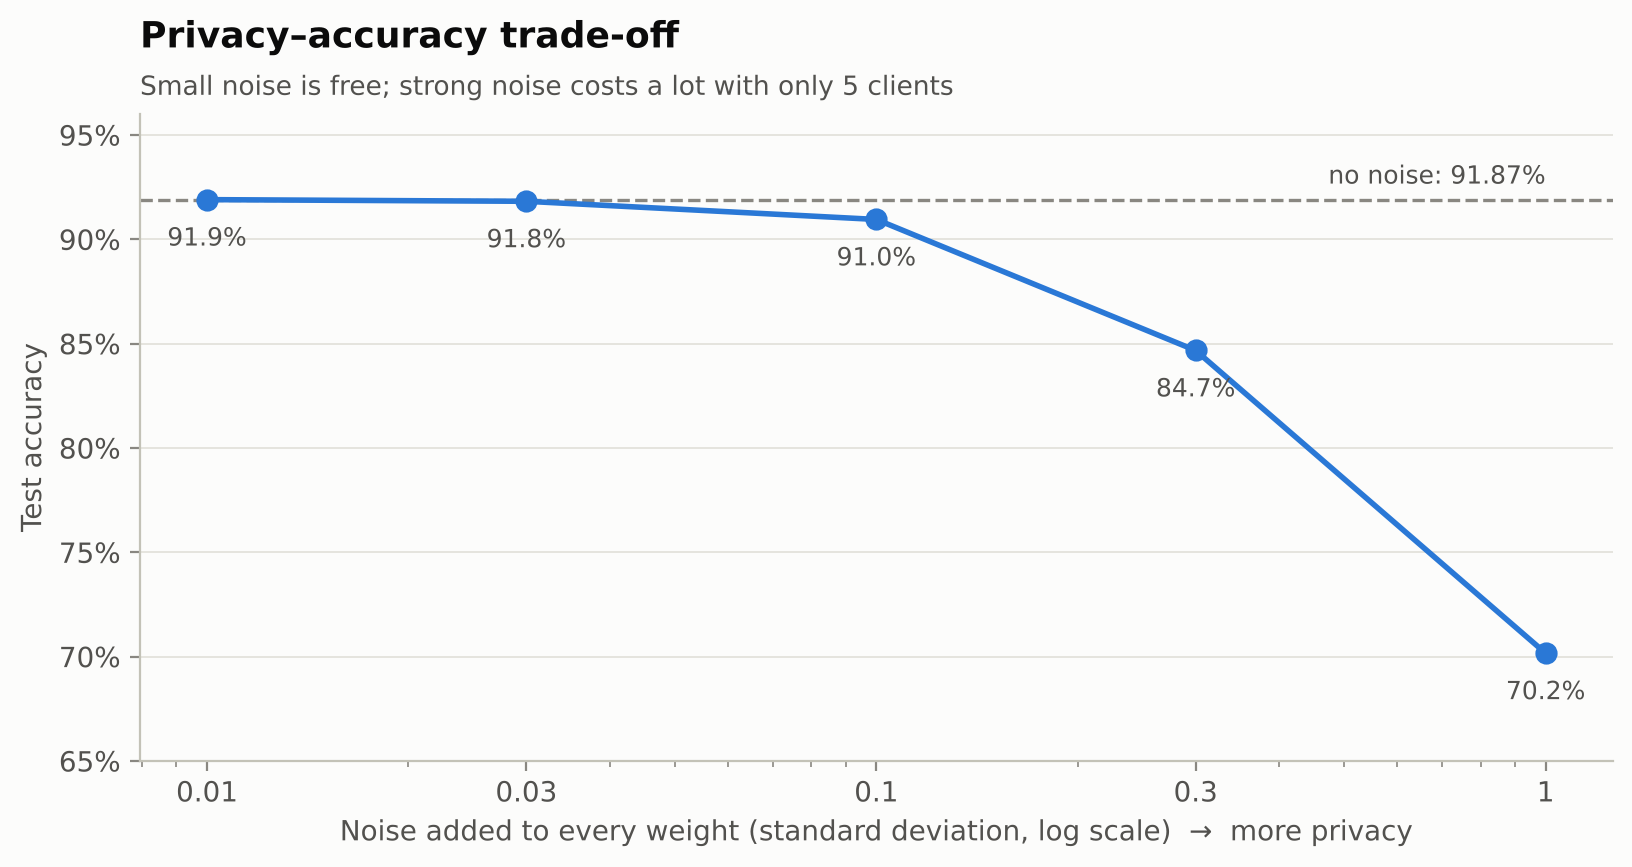

In [8]:
base_acc = noise.loc[noise.noise_std_per_weight == 0, "accuracy"].iloc[0]
nz = noise[noise.noise_std_per_weight > 0]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.axhline(base_acc, color=MUTED, lw=1.2, ls="--")
ax.text(1.0, base_acc + 0.008, f"no noise: {base_acc:.2%}", ha="right", fontsize=9, color=INK2)
ax.plot(nz.noise_std_per_weight, nz.accuracy, color=BLUE, lw=2, marker="o", ms=7)
for x, y in zip(nz.noise_std_per_weight, nz.accuracy):
    ax.text(x, y - 0.022, f"{y:.1%}", ha="center", fontsize=9, color=INK2)
ax.set_xscale("log"); ax.set_xticks(nz.noise_std_per_weight, [f"{v:g}" for v in nz.noise_std_per_weight])
ax.set_xlabel("Noise added to every weight (standard deviation, log scale)  →  more privacy")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylim(0.65, 0.96); ax.set_ylabel("Test accuracy")
ax.grid(axis="x", visible=False)
title(ax, "Privacy–accuracy trade-off", "Small noise is free; strong noise costs a lot with only 5 clients")
fig.savefig(FIG / "G5_privacy_noise_tradeoff.png"); plt.show()

- Noise up to **0.03 per weight costs almost nothing** (91.8%).
- At **0.1** accuracy drops to 91.0%, at **0.3** to 84.7%, and at **1.0** to 70.2%.
- **Why so costly?** Noise is averaged over only **5 clients**. Real federated systems with thousands of clients can add much stronger protection for the same accuracy loss.
- **Honest note:** we show the trade-off but did **not** compute a formal privacy guarantee (ε). That would need a privacy accountant and is listed as future work.

## 6. Final summary – Objective 3

In [9]:
fin = main.set_index("method").loc[["Centralized (pooled data)", "FedAvg – platform clients (non-IID)",
                                    "FedAvg – random clients (IID)", "Local only – average of 5 platforms"]]
out = pd.DataFrame({
    "Method": ["Centralized", "Federated (FedAvg, platform clients)", "Federated (FedAvg, IID clients)", "Local only (average)"],
    "Raw data shared?": ["Yes – all comments", "No", "No", "No"],
    "Accuracy": fin.accuracy_mean.values, "Precision": fin.precision.values, "Recall": fin.recall.values, "Macro-F1": fin.macro_f1_mean.values})
out.to_csv(TAB / "final_comparison_table.csv", index=False)
out.style.format({c: "{:.2%}" for c in ["Accuracy", "Precision", "Recall", "Macro-F1"]}).hide(axis="index")

Method,Raw data shared?,Accuracy,Precision,Recall,Macro-F1
Centralized,Yes – all comments,92.25%,92.35%,92.25%,92.22%
"Federated (FedAvg, platform clients)",No,91.94%,92.03%,91.94%,91.91%
"Federated (FedAvg, IID clients)",No,92.00%,92.09%,92.00%,91.97%
Local only (average),No,90.50%,90.60%,90.50%,90.47%


### Conclusions
1. **Federated learning works:** 91.94% accuracy, within about 0.3 points of centralized training, with **zero comments shared**.
2. **Collaboration pays:** FedAvg beats every platform training alone, by up to **3.2 points** (NewsPortal) and **1.4 points** on average.
3. **The biggest winners are clients with unusual data**, for example the English-only NewsPortal on Hinglish comments (+7.6 points).
4. **Non-IID data had little effect here**, and FedProx was not needed for this model and dataset.
5. **Extra privacy has a price:** small noise is free, strong noise is expensive with only 5 clients.

**Limitations:** synthetic (though incident-grounded) data, only 5 simulated clients on one machine, a linear model, and no formal ε privacy accounting.

**Next:** Step 9 – demo app and presentation.